In [41]:
# imports

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from pathlib import Path


In [12]:
# read in HLII presence/absence data

hlii_complete_df = pd.read_csv('../data/subsets/hlii_presence_absence_data_complete.csv', index_col=0)
hlii_incomplete_df = pd.read_csv('../data/subsets/hlii_presence_absence_data_incomplete.csv', index_col=0)
genome_metadata_df = pd.read_csv('../data/pro_pangenome_metadata.csv')
completeness_series = genome_metadata_df.set_index('genome')['completeness'] / 100

hlii_complete_df

,ProchlorococcusMIT9123,ProchlorococcusMIT0604,ProchlorococcusMIT9302,ProchlorococcusMIT9116,ProchlorococcusMIT9314,ProchlorococcusMIT9201,ProchlorococcusMIT9311,ProchlorococcusMIT9215,ProchlorococcusMIT1314,ProchlorococcusSB,ProchlorococcusMIT9301,ProchlorococcusGP2,ProchlorococcusMIT9312,ProchlorococcusMIT9322,ProchlorococcusAS9601,ProchlorococcusMIT9401,ProchlorococcusMIT9321
gene_cluster_id,,,,,,,,,,,,,,,,,
GC_00000001,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
GC_00000002,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
GC_00000003,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
GC_00000004,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
GC_00000005,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [24]:
# function to estimate gene family prevalence using a Bernoulli model

def estimate_prevalence_bernoulli(data, lambdas):
    """
    Estimate gene family prevalence using a Bernoulli model.
    
    Parameters:
    data (pd.DataFrame): A DataFrame containing presence/absence data for gene families across genomes.
    lambdas (pd.Series): A series of lambda values corresponding to the completeness of each genome
        in the dataset, with values between 0 and 1.
    
    Returns:
    pd.Series: A series of pi values representing the estimated prevalence of each gene family.
    """
    # Ensure that the index of lambdas matches the columns of data
    if not all(lambdas.index == data.columns):
        raise ValueError("The index of lambdas must match the columns of data.")
    
    # Ensure the presence/absence data is binary (0 and 1)
    data = data.astype(int)  # Convert to integer type if not already
    if not data.map(lambda x: x in [0, 1]).all().all():
        raise ValueError("Data must be binary (0 and 1).")
    
    # Calculate inverse of the lambda values
    inverse_lambdas = 1 / lambdas

    # Multiply the presence/absence data by the inverse of the lambda values
    weighted_data = data.multiply(inverse_lambdas, axis=1)

    # Estimate the prevalence (pi) for each gene family as the expected value of the weighted presence/absence data
    pi_estimates = weighted_data.mean(axis=1)
    
    return pi_estimates

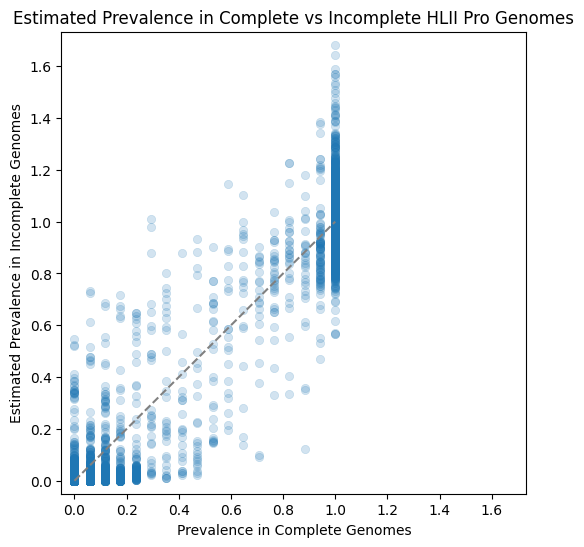

In [32]:
# plot pi estimates against ground truth prevalence values

# calculate pi estimates for incomplete genomes
lambdas_incomplete = estimate_prevalence_bernoulli(
    data=hlii_incomplete_df, 
    lambdas=completeness_series.loc[hlii_incomplete_df.columns]
)

# calculate ground truth prevalence values from complete genomes
ground_truth = hlii_complete_df.mean(axis=1)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(x=ground_truth, y=lambdas_incomplete, alpha=0.2, edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 1], [0, 1], '--', color='gray')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('Prevalence in Complete Genomes')
plt.ylabel('Estimated Prevalence in Incomplete Genomes')
plt.title('Estimated Prevalence in Complete vs Incomplete HLII Pro Genomes')

# Show the plot
# plt.grid()
plt.show()

In [36]:
# evaluate estimator statistics 

residuals = ground_truth - lambdas_incomplete
mse = np.mean(residuals ** 2)
rmse =  np.sqrt(mse)

print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')

MSE: 0.0013
RMSE: 0.0361


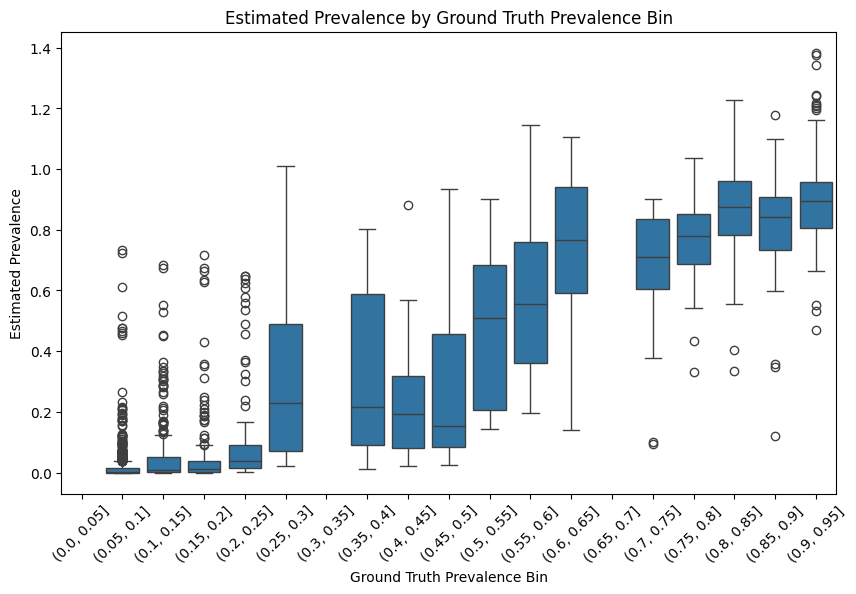

In [40]:
# plot binned boxplots of pi estimates vs ground truth prevalence values

# Create a DataFrame for plotting
plot_df = pd.DataFrame({
    'Ground Truth Prevalence': ground_truth,
    'Estimated Prevalence': lambdas_incomplete
})  

# Create bins for the ground truth prevalence
bins = np.arange(0, 1.0, 0.05)
plot_df['Prevalence Bin'] = pd.cut(plot_df['Ground Truth Prevalence'], bins=bins)
# Create a boxplot of estimated prevalence for each bin of ground truth prevalence
plt.figure(figsize=(10, 6))
sns.boxplot(x='Prevalence Bin', y='Estimated Prevalence', data=plot_df)
plt.xticks(rotation=45)
plt.xlabel('Ground Truth Prevalence Bin')
plt.ylabel('Estimated Prevalence')
plt.title('Estimated Prevalence by Ground Truth Prevalence Bin')
plt.show()

In [ ]:
# read in simulated pangenome data

sim_data_dir = Path('../data/simulated')
simulated_pangenome_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_data.csv', index_col=0)
simulated_completeness = pd.read_csv(
    sim_data_dir / 'simulated_completeness.csv', index_col=0)['completeness'] / 100

# ground truth prevalence values for simulated data come from complete genomes
pa_complete_df = pd.read_csv('../data/subsets/pro_presence_absence_data_complete.csv', index_col=0)

simulated_pangenome_df


,sim_genome_0,sim_genome_1,sim_genome_2,sim_genome_3,sim_genome_4,sim_genome_5,sim_genome_6,sim_genome_7,sim_genome_8,sim_genome_9,...,sim_genome_990,sim_genome_991,sim_genome_992,sim_genome_993,sim_genome_994,sim_genome_995,sim_genome_996,sim_genome_997,sim_genome_998,sim_genome_999
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,0,1,0,0,0,1,1,0,1,1,...,1,0,1,0,0,1,0,1,0,0
GC_00000002,0,1,0,0,1,1,0,1,0,1,...,1,0,1,0,0,0,0,0,0,1
GC_00000003,1,1,1,0,1,1,1,0,1,1,...,0,0,0,1,0,0,1,1,0,1
GC_00000004,0,1,0,0,1,1,1,0,1,1,...,0,0,0,0,0,0,1,1,0,1
GC_00000005,0,1,1,1,0,1,1,1,0,1,...,0,0,1,1,0,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


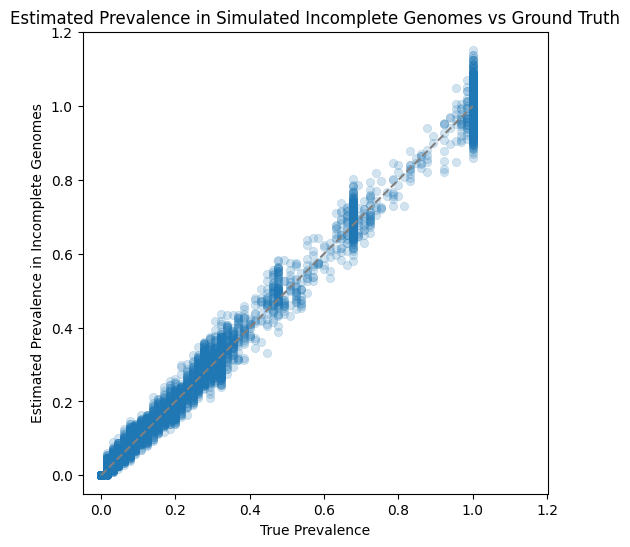

In [45]:
# run Bernoulli model on simulated data

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=simulated_pangenome_df,
    lambdas=simulated_completeness
)

# calculate ground truth prevalence values from complete genomes
ground_truth = pa_complete_df.mean(axis=1)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(x=ground_truth, y=lambdas_incomplete, alpha=0.2, edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 1], [0, 1], '--', color='gray')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('True Prevalence')
plt.ylabel('Estimated Prevalence in Incomplete Genomes')
plt.title('Estimated Prevalence in Simulated Incomplete Genomes vs Ground Truth')

# Show the plot
# plt.grid()
plt.show()
